# ngsrng tutorial: random functions on finite element spaces

`ngsrng` draws **random functions** (random fields) in NGSolve finite element spaces with numpy's sampling syntax:
`rng.normal()`, `rng.uniform()`, `rng.gamma(2.0)`, ... Every field is built from a Gaussian random field with the
spatial correlation you choose, and for every distribution the package picks a suitable algorithm automatically.

This notebook is a guided tour with pictures:

1. [Quick start: a Gaussian random field](#1.-Quick-start:-a-Gaussian-random-field)
2. [Correlation length and smoothness](#2.-Correlation-length-and-smoothness)
3. [Other distributions, numpy style](#3.-Other-distributions,-numpy-style)
4. [Where the values live: representations](#4.-Where-the-values-live:-representations)
5. [Parameters that vary in space](#5.-Parameters-that-vary-in-space)
6. [Fields of probability vectors and of matrices](#6.-Fields-of-probability-vectors-and-of-matrices)
7. [Use case: a PDE with a random coefficient](#7.-Use-case:-a-PDE-with-a-random-coefficient)
8. [Use case: a Bayesian inverse problem](#8.-Use-case:-a-Bayesian-inverse-problem)
9. [Low-rank models](#9.-Low-rank-models)
10. [Covariances given as operators: variance maps, traces, sample covariances](#10.-Covariances-given-as-operators:-variance-maps,-traces,-sample-covariances)
11. [Other settings: 1D, curved domains, boundary conditions, DG, 3D](#11.-Other-settings:-1D,-curved-domains,-boundary-conditions,-DG,-3D)
12. [Practicalities: reproducibility, speed, precision, GPU](#12.-Practicalities:-reproducibility,-speed,-precision,-GPU)
13. [What to keep in mind](#13.-What-to-keep-in-mind)

The whole notebook runs in a few minutes on a laptop CPU.

## 0. Setup

FE functions are shown with NGSolve's own `Draw` (`ngsolve.webgui`): it draws a finite element function exactly,
everywhere, and the pictures are interactive (rotate, zoom, change the colour range in the panel). Where several
fields are compared side by side, the notebook uses `ngsplot`, which paints the very same picture as `Draw` into a
matplotlib figure (static, but easy to put into a grid). matplotlib itself is only used for data that are not FE
functions: histograms and spectra.

`ngsplot` is a local package (`pip install -e /path/to/ngsplot`); `Draw` needs `anywidget` in Jupyter.

In [1]:
import ngsrng  # noqa: I001  (first: it imports torch before NGSolve, ngsrng known issue 1)
import time

import matplotlib.pyplot as plt
import ngsolve as ngs
import numpy as np
import scipy.stats as st
from ngsolve.webgui import Draw
from ngsplot import pyplot as ngsplot
from ngsplot._ngsolve import render_data


%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

# Draw's settings for random fields: no wireframe, 32 colour bands
look = {"settings": {"Objects": {"Wireframe": False}, "Colormap": {"ncolors": 32}}}


def as_gf(coefficients, space):
    # a GridFunction from a coefficient vector
    gf = ngs.GridFunction(space)
    gf.vec.FV().NumPy()[:] = np.asarray(coefficients, dtype=float)
    return gf


def panels(fields, titles, ncols=None, mesh=None, size=3.4, **kw):
    # Draw-identical pictures side by side (ngsplot). fields: GridFunctions, CoefficientFunctions (with mesh=),
    # payloads from render_data, or (field, options) pairs for per-panel options such as vmin / vmax
    ncols = ncols or len(fields)
    nrows = -(-len(fields) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.3 * size * ncols, size * nrows), squeeze=False)
    for ax, f, title in zip(axes.ravel(), fields, titles):
        f, options = f if isinstance(f, tuple) else (f, {})
        if isinstance(f, dict):  # a payload built with render_data (e.g. a 1D graph)
            ngsplot.Plot(f, ax=ax, colorbar=False, width=420, height=360, **kw, **options)
        else:
            extra = {} if isinstance(f, ngs.GridFunction) else {"mesh": mesh}
            ngsplot.Plot(f, ax=ax, colorbar=True, width=420, height=360, **extra, **look, **kw, **options)
        ax.set_title(title)
    for ax in axes.ravel()[len(fields):]:
        ax.axis("off")
    plt.show()


def graph(f, scale=0.15):
    # a function on a 1D mesh, drawn as its graph: Draw's deformation moves the line to (x, scale * f(x))
    return render_data(f, deformation=ngs.CF((0, scale * f)), **look)


print("ngsrng ready; NGSolve", ngs.__version__)

ngsrng ready; NGSolve 6.2.2608


## 1. Quick start: a Gaussian random field

A generator is created for an FE space, with a seed and a **correlation**. `matern_correlation(length, nu)` is the
Matérn correlation: `length` is the distance at which values are nearly uncorrelated (correlation about 0.13),
`nu` is the smoothness. It is normalised so that the field has variance about 1 away from the boundary.

`rng.normal()` returns one sample as a `GridFunction`, ready for `Draw`:

In [2]:
mesh = ngs.Mesh(ngs.unit_square.GenerateMesh(maxh=0.04))
V = ngs.H1(mesh, order=2)

rng = ngsrng.default_rng(V, seed=1, correlation=ngsrng.matern_correlation(0.2, nu=1.0))
u = rng.normal()
Draw(u, **look);

With `size=` it returns an array of coefficient vectors, one row per sample, like numpy:

(3, 3013) float32 | ndof: 3013


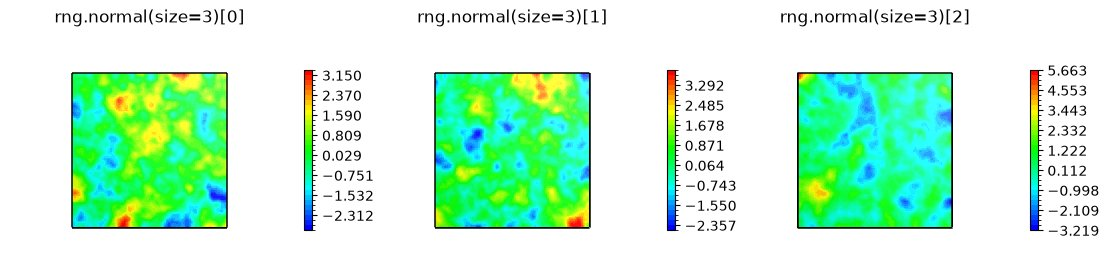

In [3]:
U = rng.normal(size=3)
print(U.shape, U.dtype, "| ndof:", V.ndof)
panels([as_gf(U[k], V) for k in range(3)], [f"rng.normal(size=3)[{k}]" for k in range(3)])

The Gaussian behind the generator is an ordinary `ngsrng.Gaussian`; printing it shows which algorithms were chosen
automatically (white-noise sampler, solver, ...). Mean and scale work as in numpy, and the mean can be any
CoefficientFunction:

In [4]:
print(rng.gaussian())
Draw(rng.normal(loc=ngs.sin(2 * np.pi * ngs.x), scale=0.3), **look);

Gaussian(
  space: H1(order=2) on 2D mesh, 1456 elements, ndof=3013, free=3013
  engine: ngsolve
  device: cpu
  dtype: torch.float32
  structure: C = A^-2: white noise + 1 solve(s) per sample
  noise: local-gram-explicit
  nrand: 8736
  exact: True
  solver: ngsolve-direct(sparsecholesky)
)


## 2. Correlation length and smoothness

Larger `length` gives larger features; larger `nu` gives smoother fields. The mesh should resolve the correlation
length (mesh size at most about a quarter of `length`), so this section uses a finer first-order mesh.

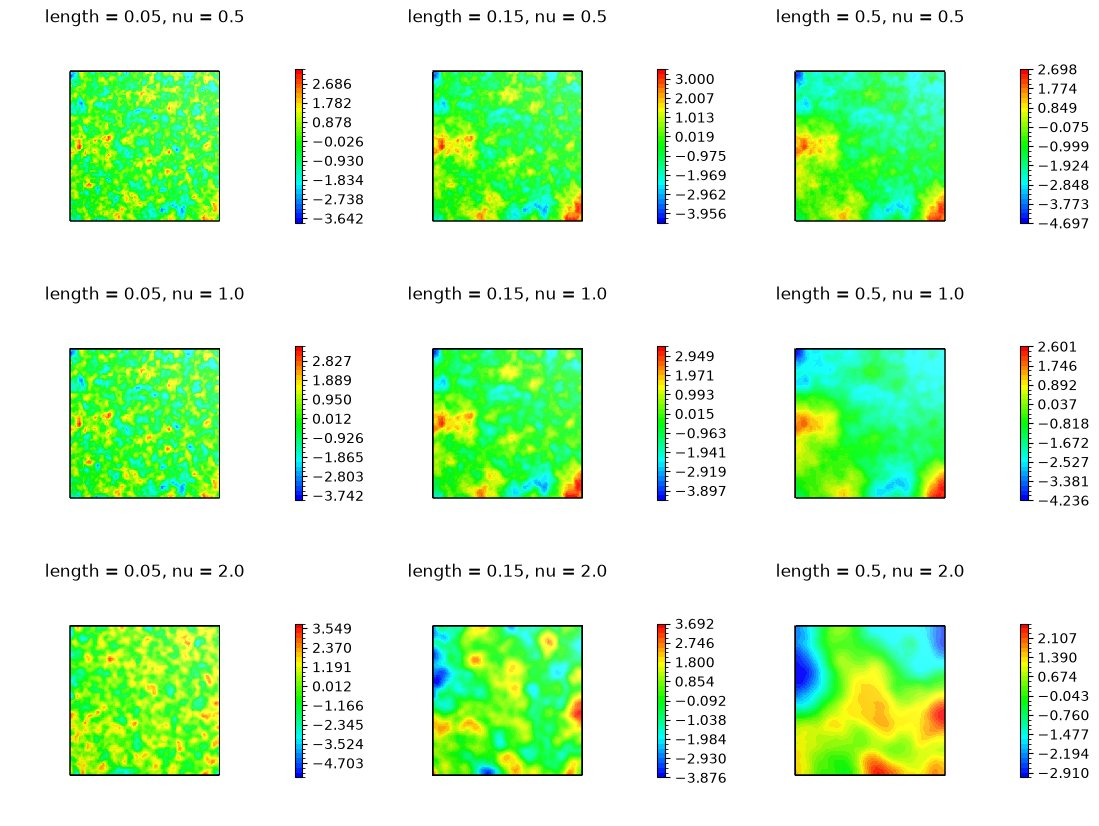

In [5]:
fine = ngs.Mesh(ngs.unit_square.GenerateMesh(maxh=0.015))
V1 = ngs.H1(fine, order=1)
fields, titles = [], []
for nu in (0.5, 1.0, 2.0):
    for length in (0.05, 0.15, 0.5):
        r = ngsrng.default_rng(V1, seed=7, correlation=ngsrng.matern_correlation(length, nu=nu))
        fields.append(r.normal())
        titles.append(f"length = {length}, nu = {nu}")
panels(fields, titles, ncols=3)

The variance is 1 in the interior, but it grows towards the boundary: the natural (Neumann) boundary condition
roughly doubles it at edges and corners. No sampling is needed to see this. The variance at a point $x$ is the
diagonal $k(x,x)$ of the covariance kernel $k(x,y)$, and on each element it only involves the covariance between that
element's unknowns. `ngsrng.pointwise_variance` computes those and returns the variance as an FE function (of twice
the order), exact everywhere. With `"exact"` it costs one solve per unknown:

In [6]:
r = ngsrng.default_rng(V1, seed=2, correlation=ngsrng.matern_correlation(0.15, nu=1.0), dtype="float64")
g = r.gaussian()
t0 = time.time()
var = ngsrng.pointwise_variance(g, "exact")                  # GridFunction of L2(order 2): exact
print(f"exact variance map: {time.time() - t0:.0f} s for {V1.ndof} unknowns")
Draw(ngs.sqrt(var), fine, **look);                           # the pointwise standard deviation

exact variance map: 16 s for 5306 unknowns


For comparison, the classic estimate from 400 samples (on first-order elements the coefficients are the values at
the vertices, so the sample standard deviation is again an FE function), and the default method for large problems,
`"lowrank"`: the dominant part of the covariance exactly, the rest from 32 samples. For this short correlation length
the low-rank part captures little, so it is about as noisy as plain sampling; for smooth fields it is far more accurate
(see the README):

relative L2 error of the variance: 400 samples 7.6%; low rank 5.2% (low rank 100 (exact) + Monte Carlo residual (32 samples), 732 solves)


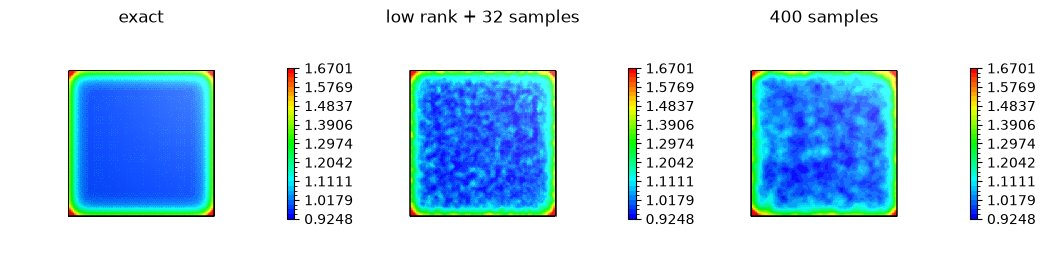

In [7]:
std_mc = as_gf(r.normal(size=400).std(axis=0), V1)
lc = ngsrng.local_covariance(g, "lowrank")
var_lr = lc.variance()
rel = lambda v: np.sqrt(ngs.Integrate((v - var) ** 2, fine) / ngs.Integrate(var**2, fine))  # noqa: E731
print(f"relative L2 error of the variance: 400 samples {rel(std_mc**2):.1%}; "
      f"low rank {rel(var_lr):.1%} ({lc.method}, {lc.applications} solves)")
lo, hi = np.percentile(std_mc.vec.FV().NumPy(), [0.5, 99.5])
panels([(ngs.sqrt(var), dict(vmin=lo, vmax=hi)), (ngs.sqrt(ngs.IfPos(var_lr, var_lr, 0)), dict(vmin=lo, vmax=hi)),
        (std_mc, dict(vmin=lo, vmax=hi))],
       ["exact", "low rank + 32 samples", "400 samples"], mesh=fine, size=3.2)

**What the correlation length means.** `covariance_function(gaussian, x0)` is the column $k(x_0,\cdot)$ of the
kernel (one solve); with `correlation=True` it is divided by the standard deviations. In the middle of the domain the
correlation drops to about 0.14 at distance `length`; near the boundary, the boundary condition changes its shape and
reach:

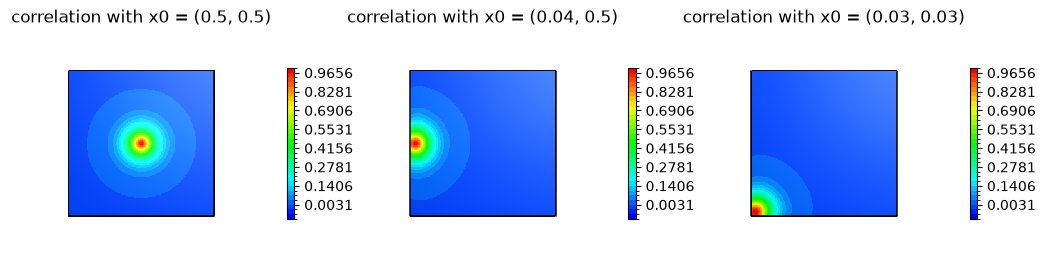

In [8]:
x0s = [(0.5, 0.5), (0.04, 0.5), (0.03, 0.03)]
panels([(ngsrng.covariance_function(g, x0, correlation=True), dict(vmin=-0.1, vmax=1)) for x0 in x0s],
       [f"correlation with x0 = {x0}" for x0 in x0s], mesh=fine, size=3.2)

## 3. Other distributions, numpy style

All of numpy's distributions are available under numpy's names and parameters, plus a few that are natural for
fields (Student-t processes, normal-inverse-Gaussian fields, Wishart and Dirichlet fields, indicators, any
scipy.stats distribution). `rng.sample(name, ...)` accepts numpy, scipy and torch names alike.

A field like `rng.gamma(2.0)` has a gamma distribution **at every single point**, and its values at nearby points
move together according to the correlation. Below, `representation="bernstein"` asks for an FE function that stays
inside the distribution's range everywhere (more about representations in section 4).

6.0 s, including the one-off set-up of the exact pointwise standard deviation


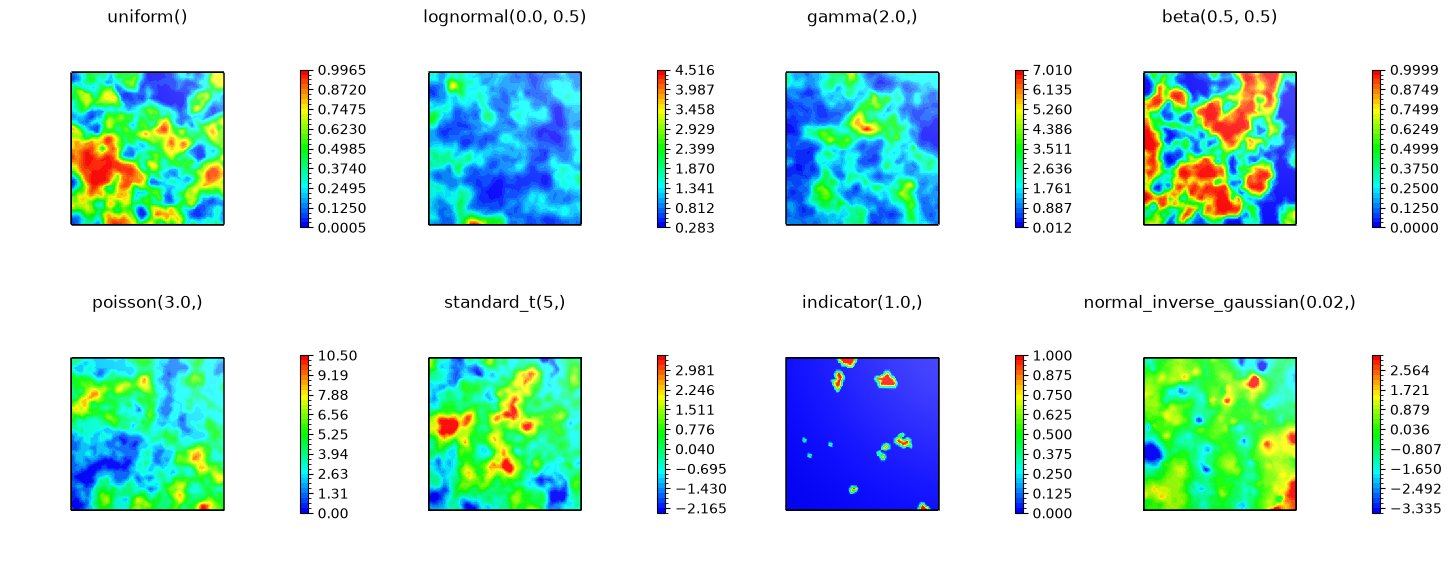

In [9]:
examples = [
    ("uniform", (), {}),
    ("lognormal", (0.0, 0.5), {}),
    ("gamma", (2.0,), {}),
    ("beta", (0.5, 0.5), {}),
    ("poisson", (3.0,), {}),
    ("standard_t", (5,), {"construction": "copula"}),
    ("indicator", (1.0,), {}),
    ("normal_inverse_gaussian", (0.02,), {}),
]
t0 = time.time()
fields = [rng.sample(name, *args, representation="bernstein", **kw) for name, args, kw in examples]
print(f"{time.time() - t0:.1f} s, including the one-off set-up of the exact pointwise standard deviation")
# heavy-tailed fields: colour range from the 1% and 99% quantiles of the vertex values (their extremes go further)
vertex = mesh.nv
robust = {name: (f, {"vmin": np.quantile(f.vec.FV().NumPy()[:vertex], 0.01),
                     "vmax": np.quantile(f.vec.FV().NumPy()[:vertex], 0.99)})
          for (name, _, _), f in zip(examples, fields) if name in ("standard_t", "normal_inverse_gaussian")}
panels([robust.get(name, f) for (name, _, _), f in zip(examples, fields)],
       [f"{name}{args}" for name, args, _ in examples], ncols=4)

Is the distribution at a point really what the name says? `points=` gives values at any coordinates you choose.
Here are 3000 samples at the point (0.3, 0.6), compared with the target density (plain data, so matplotlib):

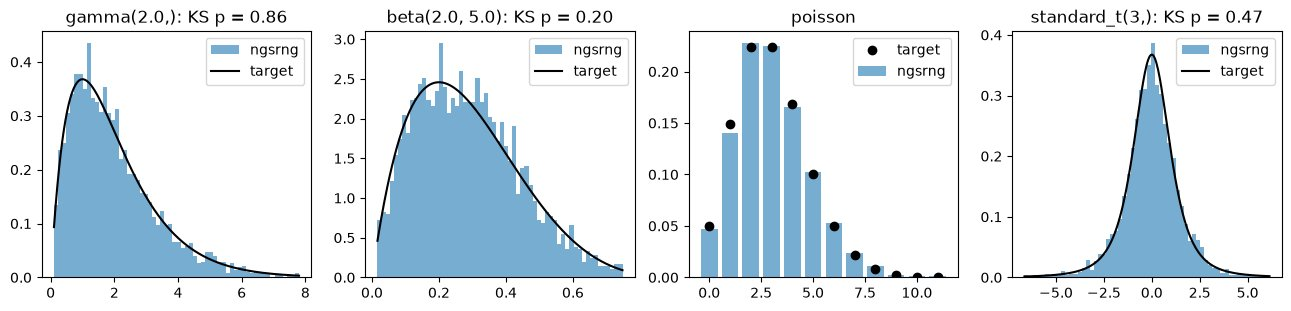

In [10]:
p = [[0.3, 0.6]]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
checks = [("gamma", (2.0,), {}, st.gamma(2.0)), ("beta", (2.0, 5.0), {}, st.beta(2.0, 5.0)),
          ("poisson", (3.0,), {}, st.poisson(3.0)), ("standard_t", (3,), {"construction": "copula"}, st.t(3))]
for ax, (name, args, kw, ref) in zip(axes, checks):
    x = rng.sample(name, *args, size=3000, points=p, **kw)[:, 0]
    if name == "poisson":
        k = np.arange(12)
        ax.bar(k, np.bincount(x.astype(int), minlength=12)[:12] / len(x), alpha=0.6, label="ngsrng")
        ax.plot(k, ref.pmf(k), "ko", label="target")
        ax.set_title(name)
    else:
        lo, hi = np.quantile(x, [0.005, 0.995])
        ax.hist(x, bins=60, range=(lo, hi), density=True, alpha=0.6, label="ngsrng")
        g = np.linspace(lo, hi, 300)
        ax.plot(g, ref.pdf(g), "k", label="target")
        ax.set_title(f"{name}{args}: KS p = {st.kstest(x, ref.cdf).pvalue:.2f}")
    ax.legend()
plt.show()

Names, aliases and what was chosen:

In [11]:
for name, args in (("gaussian", ()), ("chi2", (3,)), ("StudentT", (4,))):
    print(f"rng.sample({name!r}, ...):", rng.sample(name, *args, size=2).shape)
beta = rng.distribution("beta", 2.0, 5.0)    # a frozen distribution
beta.sample(10)                              # the algorithm is chosen on the first draw
print({k: beta.info[k] for k in ("law", "inversion", "standardisation", "representation")})

rng.sample('gaussian', ...): (2, 3013)
rng.sample('chi2', ...): (2, 36400)
rng.sample('StudentT', ...): (2, 3013)
{'law': 'Gaussian copula, beta marginals', 'inversion': 'table', 'standardisation': 'exact', 'representation': 'quadrature'}


## 4. Where the values live: representations

There is no such thing as a uniformly random *function*: a uniform field is uniform at each single point. So a
non-Gaussian field must say where its values live. `ngsrng` offers:

| representation | what you get | exact distribution | stays in the allowed range |
|---|---|---|---|
| `"quadrature"` (default) | values at the quadrature points; use as a coefficient with `rng.dx()` | at every stored point | yes |
| `points=...` | values at coordinates you choose | at every point | yes |
| `"bernstein"` | an FE function (any order, dimension, curved geometry) | at the mesh vertices; slightly smoothed in between | **everywhere** |
| `"projection"` | plain L2 projection into the FE space | no (smoothed) | **no**: can over- and undershoot |

The quadrature and point representations are values at points, not functions, so there is nothing to `Draw`. The
two FE representations of a uniform field with a short correlation, on discontinuous linear elements (look at the
colour bars):

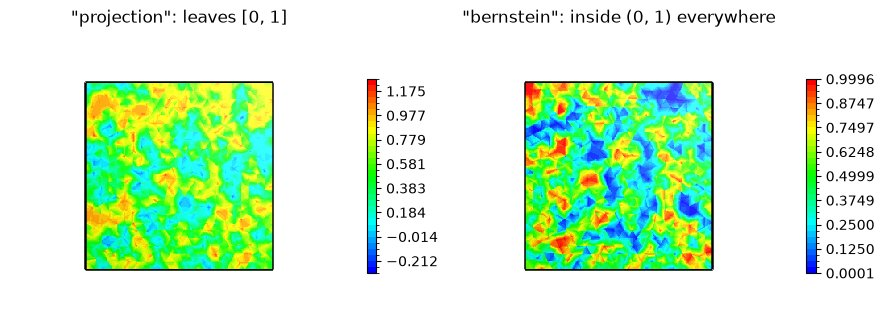

In [12]:
W = ngs.L2(ngs.Mesh(ngs.unit_square.GenerateMesh(maxh=0.05)), order=1, dgjumps=True)
r1 = ngsrng.default_rng(W, seed=11, correlation=ngsrng.matern_correlation(0.08, nu=1.0), dtype="float64")
panels([r1.uniform(representation="projection"), r1.uniform(representation="bernstein")],
       ['"projection": leaves [0, 1]', '"bernstein": inside (0, 1) everywhere'], size=4)

Over 100 samples, evaluated on a dense set of points in every element:

In [13]:
ref_points = [(a, b, 0) for a in np.linspace(0, 1, 9) for b in np.linspace(0, 1, 9) if a + b <= 1]
mp = W.mesh.MapToAllElements(ngs.IntegrationRule(ref_points, [1.0] * len(ref_points)), ngs.VOL)
for rep in ("projection", "bernstein"):
    v = np.concatenate([np.asarray(as_gf(c, W)(mp)).ravel() for c in r1.uniform(size=100, representation=rep)])
    print(f"{rep:10s}: smallest value {v.min():+.2e}, largest value 1 {v.max() - 1:+.2e}, "
          f"fraction of points outside [0, 1]: {np.mean((v < 0) | (v > 1)):.2%}")

projection: smallest value -5.03e-01, largest value 1 +4.62e-01, fraction of points outside [0, 1]: 3.75%


bernstein : smallest value +2.43e-06, largest value 1 -9.30e-07, fraction of points outside [0, 1]: 0.00%


## 5. Parameters that vary in space

Every distribution parameter can be a CoefficientFunction (or a GridFunction, or an array of point values), so the
marginal distribution can change across the domain:

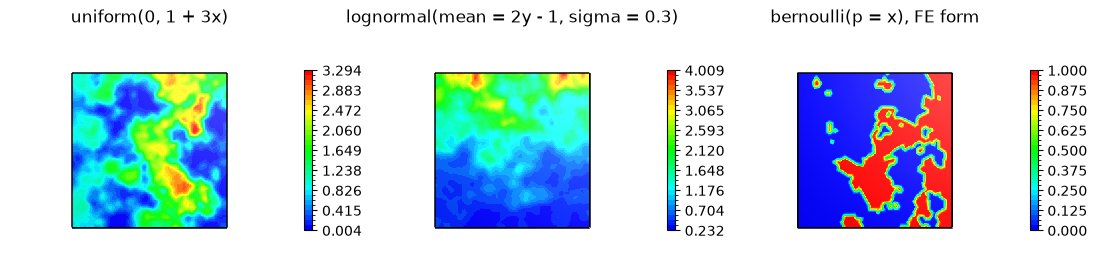

In [14]:
panels([rng.uniform(0.0, 1.0 + 3.0 * ngs.x, representation="bernstein"),
        rng.lognormal(mean=2.0 * ngs.y - 1.0, sigma=0.3, representation="bernstein"),
        rng.bernoulli(ngs.x, representation="bernstein")],
       ["uniform(0, 1 + 3x)", "lognormal(mean = 2y - 1, sigma = 0.3)", "bernoulli(p = x), FE form"])

A Bernoulli field is 0 or 1 at every point; as a Bernstein FE function it is 0 or 1 at the mesh vertices and
averages them in between, so it shows the excursion regions with soft edges.

## 6. Fields of probability vectors and of matrices

**Dirichlet fields** have values on the probability simplex (non-negative components summing to one), e.g. for
material fractions. **Wishart fields** have symmetric positive-definite matrix values, e.g. for anisotropic
conductivity tensors. In the Bernstein form, every component is an FE function, and every point of the field stays
on the simplex, respectively positive definite.

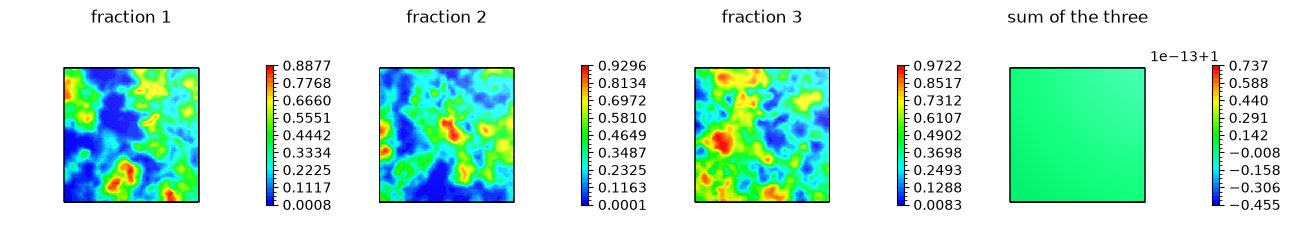

In [15]:
fractions = rng.dirichlet([1.0, 1.0, 1.0], representation="bernstein")   # (ndof, 3) FE coefficients
F = [as_gf(fractions[:, k], V) for k in range(3)]
panels(F + [F[0] + F[1] + F[2]], ["fraction 1", "fraction 2", "fraction 3", "sum of the three"], ncols=4, size=3,
       mesh=mesh)

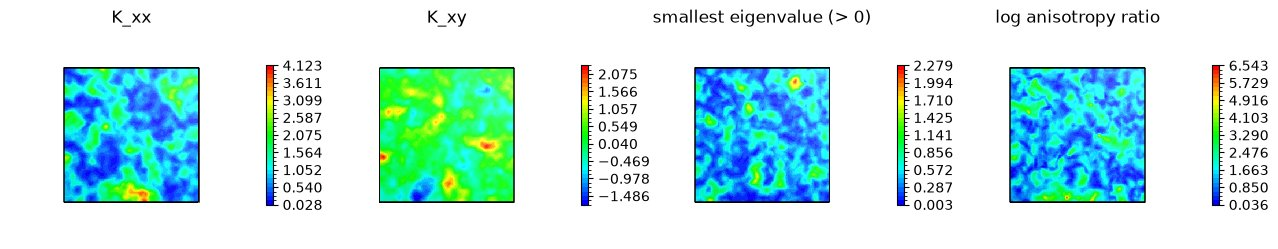

In [16]:
K = rng.wishart(4, np.eye(2) / 4, representation="bernstein")             # (ndof, 2, 2) FE coefficients
a, b, d = (as_gf(K[:, i, j], V) for i, j in ((0, 0), (0, 1), (1, 1)))
radius = ngs.sqrt(((a - d) / 2) ** 2 + b * b)
lam_max, lam_min = (a + d) / 2 + radius, (a + d) / 2 - radius
panels([a, b, lam_min, ngs.log(lam_max / lam_min)],
       ["K_xx", "K_xy", "smallest eigenvalue (> 0)", "log anisotropy ratio"], ncols=4, size=3, mesh=mesh)

## 7. Use case: a PDE with a random coefficient

Uncertainty quantification for $-\nabla\cdot(a\nabla u) = 1$ in the unit square, $u = 0$ on the boundary, with a
random log-normal diffusion coefficient $a$. The Bernstein representation is convenient here: $a$ is an ordinary FE
function (usable with any `dx`) and is guaranteed positive everywhere, so every sample gives a well-posed problem.

60 coefficient samples and PDE solves: 1.2 s


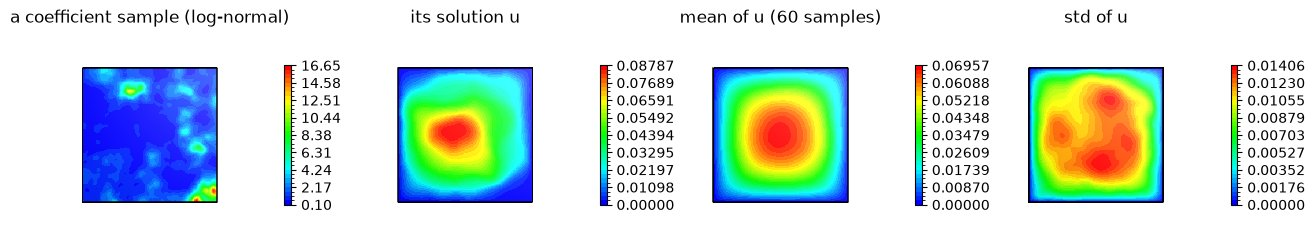

integral of u: mean 0.0331, std 0.0054


In [17]:
V0 = ngs.H1(mesh, order=2, dirichlet=".*")
u_, v_ = V0.TnT()
load = ngs.LinearForm(1.0 * v_ * ngs.dx).Assemble()
coeff = rng.distribution("lognormal", 0.0, 0.8, representation="bernstein")   # frozen: set-up done once


def solve(a):
    A = ngs.BilinearForm(a * ngs.grad(u_) * ngs.grad(v_) * ngs.dx).Assemble()
    sol = ngs.GridFunction(V0)
    sol.vec.data = A.mat.Inverse(V0.FreeDofs(), "sparsecholesky") * load.vec
    return sol


t0 = time.time()
A_samples = coeff.sample(60)                                  # (60, ndof)
solutions = [solve(as_gf(a, V)) for a in A_samples]
print(f"60 coefficient samples and PDE solves: {time.time() - t0:.1f} s")

U = np.array([s.vec.FV().NumPy() for s in solutions])
mean_u = as_gf(U.mean(0), V0)                                 # the mean of FE functions is an FE function
var_u = ngs.GridFunction(ngs.L2(mesh, order=4))               # their sample variance: degree-4 polynomials
var_u.Set(sum((s - mean_u) ** 2 for s in solutions) / len(solutions))
panels([as_gf(A_samples[0], V), solutions[0], mean_u, ngs.sqrt(ngs.IfPos(var_u, var_u, 0))],
       ["a coefficient sample (log-normal)", "its solution u", "mean of u (60 samples)", "std of u"],
       ncols=4, size=3, mesh=mesh)

qoi = np.array([ngs.Integrate(s, mesh) for s in solutions])   # quantity of interest: the integral of u
print(f"integral of u: mean {qoi.mean():.4f}, std {qoi.std():.4f}")

The default quadrature representation works too: its values are exact at the quadrature points, which is exactly
where NGSolve evaluates coefficients. It must be integrated with its own rule, `rng.dx()` (with a plain `dx`
NGSolve crashes, because the field only has values at its own points):

In [18]:
a_q = rng.lognormal(0.0, 0.8)                                 # values at quadrature points
A = ngs.BilinearForm(a_q * ngs.grad(u_) * ngs.grad(v_) * rng.dx()).Assemble()
sol = ngs.GridFunction(V0)
sol.vec.data = A.mat.Inverse(V0.FreeDofs(), "sparsecholesky") * load.vec
print("integral of u for one quadrature-represented coefficient:", round(ngs.Integrate(sol, mesh), 4))

integral of u for one quadrature-represented coefficient: 0.0252


## 8. Use case: a Bayesian inverse problem

We observe noisy **local averages** of an unknown field $f$ around 30 locations and want the posterior distribution
of $f$. With a Gaussian prior and linear observations the posterior is again Gaussian, and `ngsrng` samples it
exactly: `prior.condition(...)` returns a Gaussian that samples at about the cost of a prior sample. Its pointwise
variance is exact as well, without samples: the prior's variance (computed once) plus a low-rank correction with one
term per observation. Observations can
be any finite set of linear measurements: local averages, point values, `LinearForm`s (fluxes, boundary integrals),
matrices, or matrix-free maps through their adjoint.

exact posterior variance in 1 s: prior (exact (all columns)) + exact rank-30 update


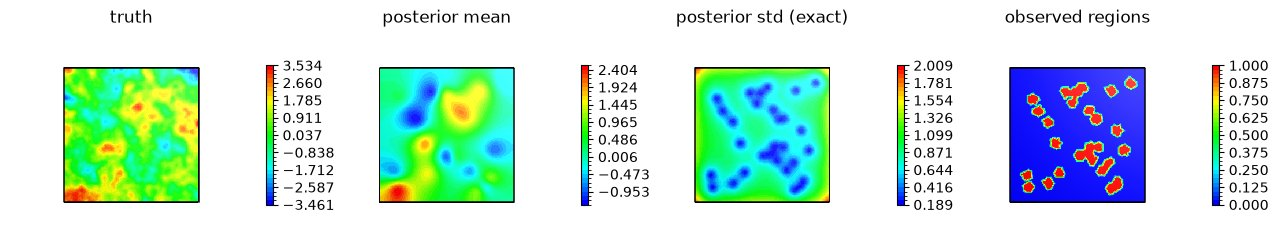

In [19]:
prior = rng.gaussian()                                        # the Matérn prior from section 1
truth = prior.sample()
centers = np.random.default_rng(0).uniform(0.1, 0.9, (30, 2))
radius, noise_sd = 0.04, 0.05
G = ngsrng.observation_operator(V, averages=(centers, radius))  # (30, ndof) observation matrix
data = G @ truth.vec.FV().NumPy() + noise_sd * np.random.default_rng(1).standard_normal(len(centers))

post = prior.condition(averages=(centers, radius), noise=noise_sd**2, data=data)
post_mean = as_gf(post.mean, V)
t0 = time.time()
post_var = ngsrng.pointwise_variance(post)                    # exact, an FE function of degree 4
print(f"exact posterior variance in {time.time() - t0:.0f} s: {ngsrng.local_covariance(post).method}")
inside = sum(ngs.IfPos(radius**2 - (ngs.x - cx) ** 2 - (ngs.y - cy) ** 2, 1.0, 0.0) for cx, cy in centers)
regions = ngs.IfPos(inside - 0.5, 1.0, 0.0)
panels([truth, post_mean, ngs.sqrt(ngs.IfPos(post_var, post_var, 0)), regions],
       ["truth", "posterior mean", "posterior std (exact)", "observed regions"], ncols=4, size=3, mesh=mesh)

Positive quantities (permeabilities, concentrations) are often modelled as $\exp$ of a Gaussian. Any distribution
can be drawn from a posterior by passing it as the correlation: the transformation is defined by the prior, so the
result is the posterior of the prior's log-normal field. Near the data the samples follow the truth; far from the
data they look like prior samples, and the posterior mean reverts towards the prior mean ($e^{1/2}\approx1.65$).

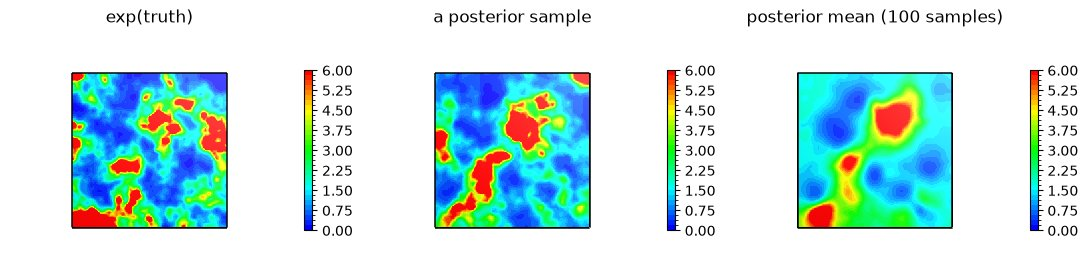

In [20]:
rng_post = ngsrng.default_rng(V, seed=3, correlation=post)
L = rng_post.lognormal(0.0, 1.0, size=100, representation="bernstein")
panels([ngs.exp(truth), as_gf(L[0], V), as_gf(L.mean(0), V)],
       ["exp(truth)", "a posterior sample", "posterior mean (100 samples)"], mesh=mesh, vmin=0, vmax=6)

## 9. Low-rank models

`karhunen_loeve(gaussian, rank)` gives the best low-rank approximation of any Gaussian (prior or posterior): its
dominant modes and their variances. By default it uses **randomised subspace iteration** on the Gaussian's factor
$L$ (with $\Sigma = LL^\top$): the sketch is re-orthonormalised after every application of $L$ and of $L^\top$, and
the eigenvalues come from an SVD, so small eigenvalues stay accurate (Aarset 2024, Algorithm 2; Halko, Martinsson &
Tropp 2011). `method="covariance"` (a range finder on the covariance with Rayleigh–Ritz) is available for comparison.

subspace iteration: 1.1 s, covariance range finder: 1.0 s; largest relative difference of the 40 leading eigenvalues: 6.0e-06


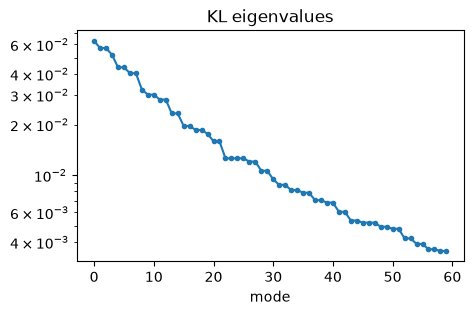

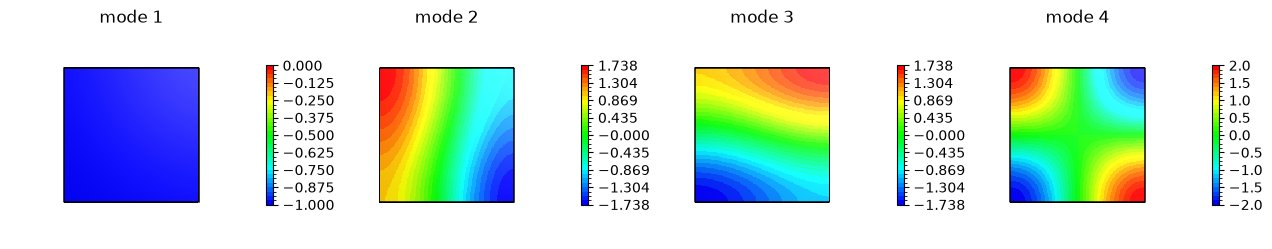

In [21]:
t0 = time.time()
kl = ngsrng.karhunen_loeve(prior, rank=60)                    # randomised subspace iteration
t_sub = time.time() - t0
t0 = time.time()
kl_cov = ngsrng.karhunen_loeve(prior, rank=60, method="covariance")
t_cov = time.time() - t0
print(f"subspace iteration: {t_sub:.1f} s, covariance range finder: {t_cov:.1f} s; largest relative difference of "
      f"the 40 leading eigenvalues: {np.max(np.abs(kl.eigenvalues[:40] / kl_cov.eigenvalues[:40] - 1)):.1e}")

fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogy(kl.eigenvalues, ".-")
ax.set_xlabel("mode"), ax.set_title("KL eigenvalues")
plt.show()
panels([as_gf(kl.modes[:, k], V) for k in range(4)], [f"mode {k + 1}" for k in range(4)], ncols=4, size=3)

The first mode is the constant function: with the natural (Neumann) boundary condition, the field's average over
the domain is its most uncertain feature.

**Non-Gaussian fields with exactly this covariance.** The distributions of section 3 transform a Gaussian field point
by point, so the covariance you choose is that of the hidden Gaussian field, not of the result. A Karhunen–Loève
expansion with independent non-Gaussian coefficients, $f = m + \sum_k \sqrt{\lambda_k}\,\xi_k\,\varphi_k$, keeps the
covariance *exactly*, for any coefficient law with mean 0 and variance 1. With uniform coefficients the field is
bounded: $|f - m| \le \sqrt3 \sum_k \sqrt{\lambda_k}\,|\varphi_k|$ everywhere (a safe but pessimistic bound). Its
value at a single point is not uniform, though: a sum of many independent terms is close to Gaussian.

Karhunen-Loeve expansion, rank 60, iid uniform coefficients (covariance exactly the Gaussian's)


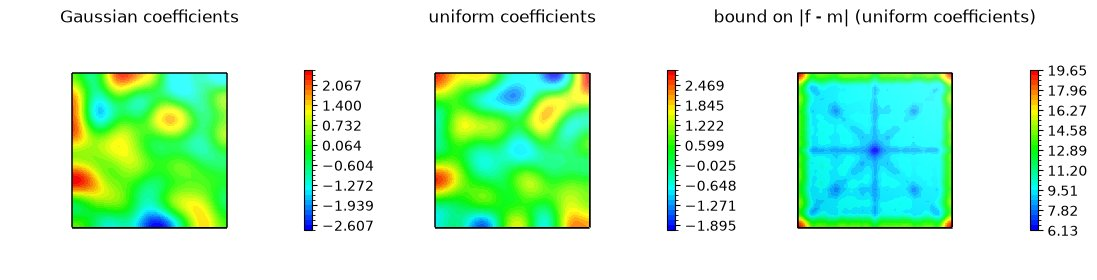

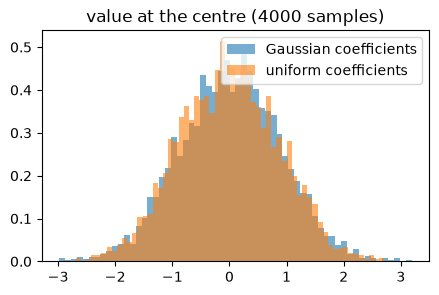

both have the same covariance; sample variances at the centre: [0.775 0.756]


In [22]:
rng_kl = ngsrng.default_rng(V, seed=11, covariance=kl, dtype="float64")   # the rank-60 expansion as a covariance
print(rng_kl.info("karhunen_loeve", "uniform")["law"])
Kg = rng_kl.karhunen_loeve("normal", size=4000)
Ku = rng_kl.karhunen_loeve("uniform", size=4000)
modes = [as_gf(m, V) for m in kl.modes.T]
bound = np.sqrt(3) * sum(np.sqrt(lam) * ngs.IfPos(m, m, -m) for lam, m in zip(kl.eigenvalues, modes))
panels([as_gf(Kg[0], V), as_gf(Ku[0], V), bound], ["Gaussian coefficients", "uniform coefficients",
       "bound on |f - m| (uniform coefficients)"], mesh=mesh, size=3.4)

centre = int(np.argmin([np.hypot(v.point[0] - 0.5, v.point[1] - 0.5) for v in mesh.vertices]))  # a vertex dof
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(Kg[:, centre], bins=60, density=True, alpha=0.6, label="Gaussian coefficients")
ax.hist(Ku[:, centre], bins=60, density=True, alpha=0.6, label="uniform coefficients")
ax.set_title("value at the centre (4000 samples)"), ax.legend()
plt.show()
print("both have the same covariance; sample variances at the centre:",
      np.round([Kg[:, centre].var(), Ku[:, centre].var()], 3))

## 10. Covariances given as operators: variance maps, traces, sample covariances

Covariances often come as operators: a PDE solve, an integral operator, a posterior from another code. If a
covariance is only available as an operator (a function that applies it), `OperatorCovariance` builds a Karhunen–Loève
expansion automatically, increasing the rank until the missing variance is below `tol` (here 5%; this Matérn field
has slowly decaying eigenvalues, so it needs a few hundred modes):

apply-only covariance: adaptive KL, rank 256, uncaptured trace ~4.1e-02


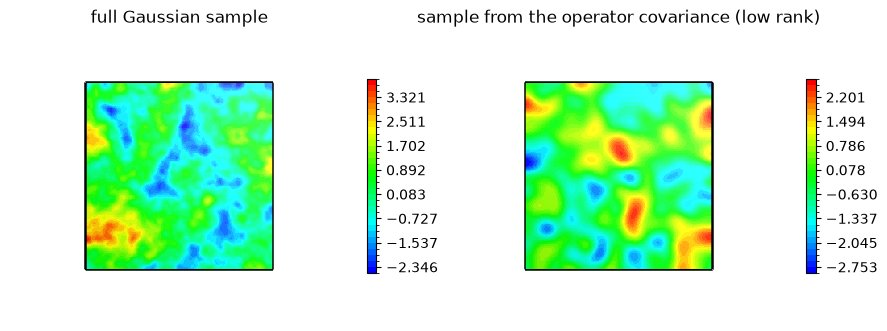

In [23]:
cov = ngsrng.OperatorCovariance(lambda y: prior.apply(prior.apply_t(y)), tol=0.05)   # Sigma y = L L^T y
rng_op = ngsrng.default_rng(V, seed=5, covariance=cov)
print(rng_op.info("normal")["gaussian"]["structure"])
panels([rng.normal(), rng_op.normal()], ["full Gaussian sample", "sample from the operator covariance (low rank)"],
       size=4)

Any NGSolve operator expression works as well, here $C = \kappa^2 A^{-1} M A^{-1}$ with $A = \kappa^2 - \Delta$ (a
Matérn-type covariance written with NGSolve's own matrices), and every distribution can be drawn with it:

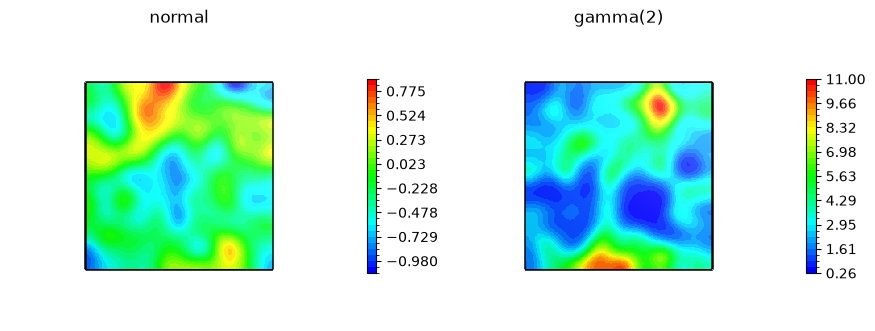

In [24]:
u_, v_ = V.TnT()
kappa = 10.0
A_op = ngs.BilinearForm(ngs.grad(u_) * ngs.grad(v_) * ngs.dx + kappa**2 * u_ * v_ * ngs.dx).Assemble()
M_op = ngs.BilinearForm(u_ * v_ * ngs.dx).Assemble()
A_inv = A_op.mat.Inverse(V.FreeDofs(), "sparsecholesky")
C = ngsrng.OperatorCovariance(kappa**2 * A_inv @ M_op.mat @ A_inv, tol=0.05)   # an NGSolve BaseMatrix
rng_C = ngsrng.default_rng(V, seed=12, covariance=C)
panels([rng_C.normal(), rng_C.gamma(2.0, representation="bernstein")], ["normal", "gamma(2)"], size=4)

**Variance maps without sampling.** The exact variance of the operator itself (one application per unknown), and the
variance of the expansion that is actually sampled (exact and free for low-rank models). The expansion misses a little
variance everywhere (the finest scales; about the 4% that `tol` allows):

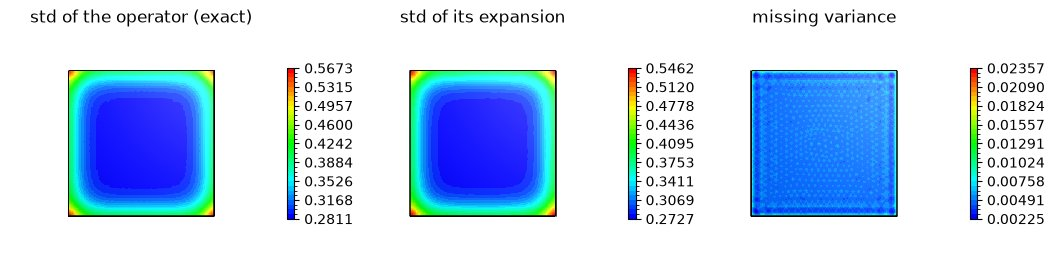

In [25]:
var_C = ngsrng.pointwise_variance(C, "exact", fes=V)
var_kl = ngsrng.pointwise_variance(rng_C.gaussian())
panels([ngs.sqrt(var_C), ngs.sqrt(ngs.IfPos(var_kl, var_kl, 0)), var_C - var_kl],
       ["std of the operator (exact)", "std of its expansion", "missing variance"], mesh=mesh, size=3.2)

**Traces.** The integral of the variance is the trace of the covariance, $\operatorname{tr} C = \int k(x,x)\,dx$:
the expected squared $L^2$ norm of a sample. With an exact variance map it is exact. Without one, randomised
estimators need only applications of the covariance: Hutchinson (the average squared norm of samples), Hutch++ and
XNysTrace. Each is run 15 times here with 60 probes. For this fairly rough field they are within a factor of two of
each other; for smooth fields (long correlation lengths) Hutch++ and XNysTrace are orders of magnitude more accurate
than Hutchinson:

exact trace 1.2215 (exact: exact (all columns))


hutchinson: 60 solves, rms relative error 1.8e-02


hutch++   : 100 solves, rms relative error 2.0e-02


xnystrace : 120 solves, rms relative error 9.6e-03


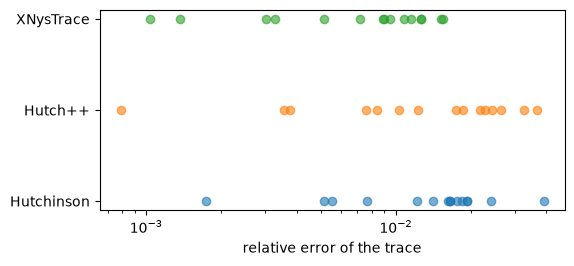

In [26]:
exact = ngsrng.covariance_trace(prior)                        # from the (cached) exact variance map of the prior
print(f"exact trace {exact.value:.4f} ({exact.method})")
fig, ax = plt.subplots(figsize=(6, 2.6))
for i, method in enumerate(("hutchinson", "hutch++", "xnystrace")):
    runs = [ngsrng.covariance_trace(prior, method, probes=60, seed=s) for s in range(15)]
    err = np.abs([e.value / exact.value - 1 for e in runs])
    ax.semilogx(err, np.full(len(err), i), "o", alpha=0.6)
    print(f"{method:10s}: {runs[0].applications} solves, rms relative error {np.sqrt(np.mean(err**2)):.1e}")
ax.set_yticks(range(3), ["Hutchinson", "Hutch++", "XNysTrace"]), ax.set_xlabel("relative error of the trace")
plt.show()

**Sample covariances (Wishart).** The sample covariance of $n$ samples is an unbiased estimate of the covariance
($n\hat C_n$ is Wishart distributed), and as a low-rank Gaussian it can be used like any other covariance: an
ensemble model, as in ensemble Kalman filters. Its weakness shows in the correlation with a fixed point: with few
samples, distant points look correlated, with errors of size $1/\sqrt n$.

n = 20: trace 1.02 x exact


n = 200: trace 0.98 x exact


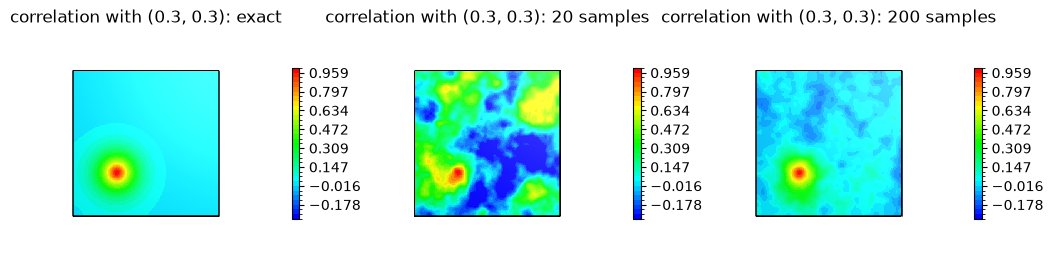

In [27]:
x0 = (0.3, 0.3)
fields, titles = [(ngsrng.covariance_function(prior, x0, correlation=True), dict(vmin=-0.3, vmax=1))], ["exact"]
for n in (20, 200):
    ens = ngsrng.sample_covariance(prior, n, seed=n)          # a LowRankGaussian of rank n
    fields.append((ngsrng.covariance_function(ens, x0, correlation=True), dict(vmin=-0.3, vmax=1)))
    titles.append(f"{n} samples")
    print(f"n = {n}: trace {ngsrng.covariance_trace(ens).value / exact.value:.2f} x exact")
panels(fields, [f"correlation with {x0}: {t}" for t in titles], mesh=mesh, size=3.2)

## 11. Other settings: 1D, curved domains, boundary conditions, DG, 3D

**1D.** Smoothness `nu` is easiest to see on a line. On a 1D mesh, `Draw`'s deformation draws a function as its
graph (here scaled by 0.15 vertically):

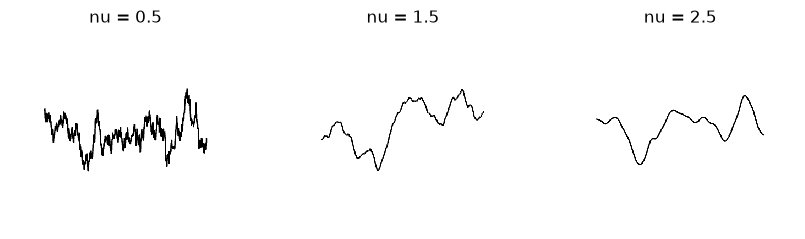

In [28]:
from ngsolve.meshes import Make1DMesh

line = Make1DMesh(400)
V1d = ngs.H1(line, order=3)
graphs = []
for nu in (0.5, 1.5, 2.5):
    r = ngsrng.default_rng(V1d, seed=4, correlation=ngsrng.matern_correlation(0.2, nu=nu))
    graphs.append(graph(r.normal()))
panels(graphs, [f"nu = {nu}" for nu in (0.5, 1.5, 2.5)], size=2.6)

**Curved domains and boundary conditions.** Boundary conditions belong to the covariance and come from the space:
a Dirichlet boundary pins Gaussian samples to their mean there. Non-Gaussian fields take the median of their
distribution at such points (0.5 for a uniform field). Curved, high-order geometry is handled throughout.

In [29]:
import netgen.geom2d as g2

geo = g2.SplineGeometry()
geo.AddCircle((0, 0), 1, bc="circle")
geo.AddRectangle((-0.3, -0.3), (0.3, 0.3), leftdomain=0, rightdomain=1, bc="hole")
disc = ngs.Mesh(geo.GenerateMesh(maxh=0.12))
disc.Curve(3)
Vd = ngs.H1(disc, order=3, dirichlet="hole")
rd = ngsrng.default_rng(Vd, seed=6, correlation=ngsrng.matern_correlation(0.4, nu=1.0))
Draw(rd.normal(), **look);

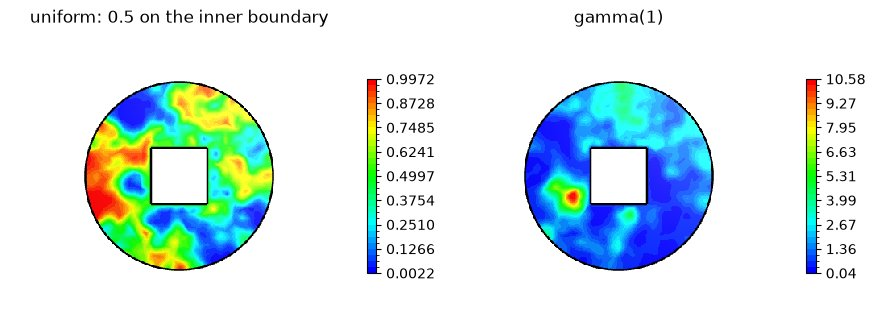

In [30]:
panels([rd.uniform(representation="bernstein"), rd.gamma(1.0, representation="bernstein")],
       ["uniform: 0.5 on the inner boundary", "gamma(1)"], size=4)

**Discontinuous (DG) spaces** work the same way; the Matérn operator is then discretised with interior penalties,
which needs `dgjumps=True`:

In [31]:
Vdg = ngs.L2(ngs.Mesh(ngs.unit_square.GenerateMesh(maxh=0.06)), order=2, dgjumps=True)
rdg = ngsrng.default_rng(Vdg, seed=8, correlation=ngsrng.matern_correlation(0.2, nu=1.0))
Draw(rdg.beta(2.0, 2.0, representation="bernstein"), **look);

**3D.** `Draw` shows a volume field on a clipping plane; drag the view to rotate, and move the plane in the panel:

In [32]:
cube = ngs.Mesh(ngs.unit_cube.GenerateMesh(maxh=0.1))
V3 = ngs.H1(cube, order=1)
r3 = ngsrng.default_rng(V3, seed=9, correlation=ngsrng.matern_correlation(0.3, nu=1.5))
t0 = time.time()
g3 = r3.gamma(2.0, representation="bernstein")
print(f"ndof {V3.ndof}: {time.time() - t0:.1f} s (including set-up)")
Draw(g3, clipping={"z": -1, "dist": 0.5}, order=1, **look);

ndof 1192: 3.9 s (including set-up)


## 12. Practicalities: reproducibility, speed, precision, GPU

* The same seed gives the same samples; `rng.spawn(n)` gives independent generators (e.g. for parallel workers).
* Results come as float32 by default (`dtype="float64"` for double precision). The Bernstein representation always
  returns float64 coefficients, because its range guarantee is about those exact numbers.
* `rng.distribution(...)` freezes a distribution: the one-off set-up (mostly computing the pointwise standard
  deviation) is done once and reused.
* On a CUDA GPU (`device="cuda"`) samples stay on the GPU as torch tensors.

In [33]:
from ngsrng.backend import cuda_usable

a = ngsrng.default_rng(V, seed=42, correlation=0.2).gamma(2.0, size=3)
b = ngsrng.default_rng(V, seed=42, correlation=0.2).gamma(2.0, size=3)
print("same seed, same samples:", np.array_equal(a, b))
child1, child2 = rng.spawn(2)
print("spawned generators differ:", not np.allclose(child1.normal(size=1), child2.normal(size=1)))

d = rng.distribution("beta", 2.0, 5.0)
for k in range(3):
    t0 = time.time()
    d.sample(50)
    print(f"call {k + 1}: 50 beta fields in {time.time() - t0:.2f} s")

if cuda_usable():
    rg = ngsrng.default_rng(V, seed=0, correlation=0.2, device="cuda")
    x = rg.gamma(2.0, size=100)
    print(type(x).__name__, x.device, x.shape)
else:
    print("No usable CUDA GPU here; with one, device='cuda' keeps everything on the GPU.")

same seed, same samples: True
spawned generators differ: True


call 1: 50 beta fields in 0.19 s
call 2: 50 beta fields in 0.19 s


call 3: 50 beta fields in 0.18 s


Tensor cuda:0 torch.Size([100, 36400])


## 13. What to keep in mind

* **Gaussian fields are exact** for the chosen mesh and element order; what remains is the usual finite element
  error. Resolve the correlation length with the mesh.
* **Non-Gaussian names describe single points.** A uniform field is uniform at each point; averages, integrals and
  other combinations of its values are not uniform.
* **The correlation you choose is that of the hidden Gaussian field.** The field you get is somewhat less correlated.
* **Choose the representation for the job**: quadrature values (with `rng.dx()`) or `points=` for exact
  distributions, `representation="bernstein"` for an FE function that never leaves the allowed range. Avoid
  `"projection"` when bounds matter.
* **The correlation must be smooth enough** for point values to exist (Matérn: `nu > 0`); `ngsrng` refuses rougher
  Matérn fields for non-Gaussian distributions.
* **Posteriors**: distributions drawn from a posterior are the posterior of the prior's transformed field, given
  linear observations of the hidden Gaussian field.
* **Variances without sampling**: `pointwise_variance` gives the exact variance map of any Gaussian, posterior or
  covariance operator, and `covariance_trace` its trace.
* **Exact covariance or exact marginals, not both**: Karhunen–Loève fields with non-Gaussian coefficients have
  exactly the given covariance; the pointwise distributions (`rng.uniform()`, ...) have exact marginals, with the
  covariance belonging to their hidden Gaussian field.
* **Sample covariances need many samples**: with $n$ samples, distant points show spurious correlations of size
  $1/\sqrt n$.

The [README](../README.md) lists every distribution with its algorithms, accuracy and speed, and the full list of
limitations.